# Week 3 Day 5 – Exercises XP Ninja
## Classification metrics from scratch (Breast Cancer)

I train a simple logistic regression model on the Breast Cancer dataset from scikit-learn. Then I compute accuracy, precision, recall and F1-score myself, using the four confusion-matrix counts (TP, TN, FP, FN). Finally I compare my functions with the official `sklearn.metrics` functions, so I can check that I understood the formulas.


## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. Run the cells from top to bottom (Shift+Enter runs one cell).
3. No file upload is needed: scikit-learn already includes the Breast Cancer dataset.


## What I do in this notebook
1. Load the Breast Cancer dataset and recode the target so that **1 = malignant** (cancer) and **0 = benign**.
2. Split the data into a training set and a test set.
3. Scale the features and train a **LogisticRegression** model.
4. Write my own accuracy, precision, recall and F1 functions from TP, TN, FP and FN.
5. Compare my results with scikit-learn and interpret what the numbers mean.


## 1. Load the data

`sklearn.datasets.load_breast_cancer` gives measurements from breast mass images. By default the target is `0 = malignant` and `1 = benign`, which I find easy to mix up. I recode it so that **1 means malignant**, because that is the class I want the model to detect.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

data = load_breast_cancer()
X = data.data
# original target: 0 = malignant, 1 = benign
# I flip it so 1 = malignant (the positive / "has cancer" class)
y = (data.target == 0).astype(int)

print("Feature matrix shape:", X.shape)
print("Number of features:", len(data.feature_names))
print("First 8 feature names:")
print(list(data.feature_names[:8]))
print()
print("Class meaning after recoding: 1 = malignant, 0 = benign")
print("Counts (0 = benign, 1 = malignant):")
print(pd.Series(y).value_counts().sort_index())
print("Share of malignant cases: "
      f"{y.mean():.1%} ({y.sum()} out of {len(y)})")


Feature matrix shape: (569, 30)
Number of features: 30
First 8 feature names:
[np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points')]

Class meaning after recoding: 1 = malignant, 0 = benign
Counts (0 = benign, 1 = malignant):
0    357
1    212
Name: count, dtype: int64
Share of malignant cases: 37.3% (212 out of 569)


## 2. Train / test split and model

I use a **stratified** split so the training set and the test set keep the same share of malignant cases. I also scale the features with `StandardScaler`, because logistic regression works better when the inputs are on a similar scale. I fit the scaler on the training set only, then I transform the test set. That way no information from the test rows leaks into training.


In [2]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])
print("Malignant share in train:", f"{y_train.mean():.1%}")
print("Malignant share in test: ", f"{y_test.mean():.1%}")

# fit the scaler on the training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# max_iter=1000 gives the solver enough steps to converge
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("Predictions on the test set are ready.")
print("Predicted malignant cases:", int(y_pred.sum()),
      "out of", len(y_pred))


Train size: 455 Test size: 114
Malignant share in train: 37.4%
Malignant share in test:  36.8%
Predictions on the test set are ready.
Predicted malignant cases: 40 out of 114


## 3. Metrics from scratch

I first count the four confusion-matrix values on the test set:

- **TP (True Positive):** predicted malignant, and it really is malignant
- **TN (True Negative):** predicted benign, and it really is benign
- **FP (False Positive):** predicted malignant, but it is actually benign (false alarm)
- **FN (False Negative):** predicted benign, but it is actually malignant (missed cancer)

Then I use the usual formulas:

- Accuracy = (TP + TN) / (TP + TN + FP + FN)
- Precision = TP / (TP + FP)
- Recall = TP / (TP + FN)
- F1 = 2 × precision × recall / (precision + recall)


In [3]:

def confusion_counts(y_true, y_pred):
    """Return TP, TN, FP, FN for a 0/1 classification problem."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return tp, tn, fp, fn


def my_accuracy(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    total = tp + tn + fp + fn
    return (tp + tn) / total if total else 0.0


def my_precision(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    return tp / (tp + fp) if (tp + fp) else 0.0


def my_recall(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    return tp / (tp + fn) if (tp + fn) else 0.0


def my_f1(y_true, y_pred):
    p = my_precision(y_true, y_pred)
    r = my_recall(y_true, y_pred)
    return (2 * p * r / (p + r)) if (p + r) else 0.0


tp, tn, fp, fn = confusion_counts(y_test, y_pred)
print("My confusion-matrix counts on the test set:")
print(f"TP = {tp}   (predicted malignant, really malignant)")
print(f"TN = {tn}   (predicted benign, really benign)")
print(f"FP = {fp}   (predicted malignant, really benign)")
print(f"FN = {fn}   (predicted benign, really malignant)")
print()
print("My metrics:")
print("Accuracy: ", round(my_accuracy(y_test, y_pred), 4))
print("Precision:", round(my_precision(y_test, y_pred), 4))
print("Recall:   ", round(my_recall(y_test, y_pred), 4))
print("F1-score: ", round(my_f1(y_test, y_pred), 4))


My confusion-matrix counts on the test set:
TP = 39   (predicted malignant, really malignant)
TN = 71   (predicted benign, really benign)
FP = 1   (predicted malignant, really benign)
FN = 3   (predicted benign, really malignant)

My metrics:
Accuracy:  0.9649
Precision: 0.975
Recall:    0.9286
F1-score:  0.9512


## 4. Compare with scikit-learn

If I understood the formulas, my numbers should match `sklearn.metrics` (or be extremely close, only because of rounding).


In [4]:

sk_acc = accuracy_score(y_test, y_pred)
sk_prec = precision_score(y_test, y_pred, zero_division=0)
sk_rec = recall_score(y_test, y_pred, zero_division=0)
sk_f1 = f1_score(y_test, y_pred, zero_division=0)

mine = {
    "Accuracy": my_accuracy(y_test, y_pred),
    "Precision": my_precision(y_test, y_pred),
    "Recall": my_recall(y_test, y_pred),
    "F1-score": my_f1(y_test, y_pred),
}
official = {
    "Accuracy": sk_acc,
    "Precision": sk_prec,
    "Recall": sk_rec,
    "F1-score": sk_f1,
}

comparison = pd.DataFrame({
    "my_function": mine,
    "sklearn": official,
})
comparison["same"] = np.isclose(
    comparison["my_function"], comparison["sklearn"]
)
display(comparison.round(4))

print("sklearn confusion matrix (rows = true class, columns = predicted class):")
print(confusion_matrix(y_test, y_pred))
print()
if comparison["same"].all():
    print("All of my functions match sklearn. The formulas are implemented correctly.")
else:
    print("There is a difference. I should re-check the formulas.")


,my_function,sklearn,same
Accuracy,0.9649,0.9649,True
Precision,0.9750,0.9750,True
Recall,0.9286,0.9286,True
F1-score,0.9512,0.9512,True


sklearn confusion matrix (rows = true class, columns = predicted class):
[[71  1]
 [ 3 39]]

All of my functions match sklearn. The formulas are implemented correctly.


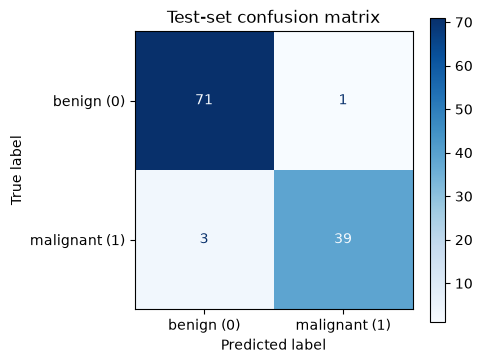

In [5]:

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["benign (0)", "malignant (1)"],
    cmap="Blues",
    ax=ax,
)
ax.set_title("Test-set confusion matrix")
plt.tight_layout()
plt.show()


## 5. Interpretation

I recoded the target so that **malignant is the positive class**. That makes the metrics easier to read in a medical setting:

- **Precision** answers: “When the model says this tumour is malignant, how often is that true?” A lower precision means more false alarms (FP): a benign case is sent for extra checks.
- **Recall** answers: “Of all the malignant tumours, how many did we catch?” A lower recall means more missed cancers (FN).
- **F1-score** is the balance between those two numbers.
- **Accuracy** is the overall share of correct predictions. It is useful, but it can look optimistic if one class is more common (here, benign cases are the majority).

A **false negative** (telling someone they are fine when the tumour is malignant) is the more serious error here, because treatment could be delayed. A **false positive** still matters — it can cause stress and extra procedures — but a second test can usually correct it. For that reason I would watch recall closely, not only accuracy.

Because my handmade functions match scikit-learn, I now trust that I understand what accuracy, precision, recall and F1 actually count. In a later project I can still use the sklearn helpers, but I know what they mean.
